<a href="https://colab.research.google.com/github/dnyaneshwari8/SiteGuard-AI/blob/branch1/model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving construction-ppe.zip to construction-ppe.zip


In [ ]:
import zipfile
import os

zip_path = "/content/construction-ppe.zip"

extract_path = "/content/construction-ppe"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['labels', 'images', 'LICENSE', 'data.yaml']


In [ ]:
import os

for root, dirs, files in os.walk("/content/construction-ppe"):
    level = root.replace("/content/construction-ppe", "").count(os.sep)

    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")

        for file in files[:5]:
            print("  " * (level + 1) + file)

construction-ppe/
  LICENSE
  data.yaml
  labels/
    val/
      image1341.txt
      image1333.txt
      image640.txt
      image1055.txt
      image396.txt
    test/
      image401.txt
      image70.txt
      image1229.txt
      image825.txt
      image1178.txt
    train/
      image1077.txt
      image940.txt
      image870.txt
      image582.txt
      image292.txt
  images/
    val/
      image698.jpg
      image628.jpg
      image876.jpg
      image65.jpeg
      image656.jpg
    test/
      image927.jpg
      image182.jpg
      image935.jpg
      image694.jpeg
      image1306.jpg
    train/
      image301.jpg
      image107.jpg
      image859.jpg
      image940.jpg
      image1015.jpg


In [ ]:
from pathlib import Path
from PIL import Image

dataset_path = Path("/content/construction-ppe")

for split in ["train", "val", "test"]:
    image_dir = dataset_path / "images" / split

    image_paths = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    corrupted = []

    for image_path in image_paths:
        try:
            with Image.open(image_path) as img:
                img.verify()
        except Exception:
            corrupted.append(image_path.name)

    print(f"\n{split.upper()} SET")
    print("Total images:", len(image_paths))
    print("Corrupted images:", len(corrupted))
    print("Examples:", corrupted[:5])


TRAIN SET
Total images: 1132
Corrupted images: 0
Examples: []

VAL SET
Total images: 143
Corrupted images: 0
Examples: []

TEST SET
Total images: 141
Corrupted images: 0
Examples: []


In [ ]:
for split in ["train", "val", "test"]:
    image_dir = dataset_path / "images" / split
    label_dir = dataset_path / "labels" / split

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    missing_labels = [
        img.name
        for img in images
        if not (label_dir / f"{img.stem}.txt").exists()
    ]

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Images without label files:", len(missing_labels))
    print("Examples:", missing_labels[:5])


TRAIN
Images: 1132
Images without label files: 0
Examples: []

VAL
Images: 143
Images without label files: 0
Examples: []

TEST
Images: 141
Images without label files: 0
Examples: []


In [ ]:
import glob

yaml_files = glob.glob(
    "/content/construction-ppe/**/*.yaml",
    recursive=True
)

print("YAML files found:", yaml_files)

YAML files found: ['/content/construction-ppe/data.yaml']


In [ ]:
with open(yaml_files[0], "r") as file:
    print(file.read())

# Ultralytics 🚀 AGPL-3.0 License - https://ultralytics.com/license

# Construction-PPE dataset by Ultralytics
# Documentation: https://docs.ultralytics.com/datasets/detect/construction-ppe/
# Example usage: yolo train data=construction-ppe.yaml
# parent
# ├── ultralytics
# └── datasets
#     └── construction-ppe ← downloads here (178.4 MB)

# Train/val/test sets as 1) dir: path/to/imgs, 2) file: path/to/imgs.txt, or 3) list: [path/to/imgs1, path/to/imgs2, ..]
path: construction-ppe # dataset root dir
train: images/train # train images (relative to 'path') 1132 images
val: images/val # val images (relative to 'path') 143 images
test: images/test # test images (relative to 'path') 141 images

# Classes
names:
  0: helmet
  1: gloves
  2: vest
  3: boots
  4: goggles
  5: none
  6: Person
  7: no_helmet
  8: no_goggle
  9: no_gloves
  10: no_boots

# Download script/URL (optional)
download: https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip




In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 61.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.5 MB/s eta 0:00:00


In [ ]:
import torch
import ultralytics

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("YOLO version:", ultralytics.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch version: 2.11.0+cu130
CUDA available: True
YOLO version: 8.4.174
GPU: Tesla T4


In [ ]:
from pathlib import Path
import yaml

dataset_path = Path("/content/construction-ppe")

config = {
    "path": str(dataset_path),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "helmet",
        1: "gloves",
        2: "vest",
        3: "boots",
        4: "goggles",
        5: "none",
        6: "Person",
        7: "no_helmet",
        8: "no_goggle",
        9: "no_gloves",
        10: "no_boots"
    }
}

config_path = dataset_path / "data_colab.yaml"

with open(config_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Configuration created:", config_path)
print(config_path.read_text())

Configuration created: /content/construction-ppe/data_colab.yaml
path: /content/construction-ppe
train: images/train
val: images/val
test: images/test
names:
  0: helmet
  1: gloves
  2: vest
  3: boots
  4: goggles
  5: none
  6: Person
  7: no_helmet
  8: no_goggle
  9: no_gloves
  10: no_boots



In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("Pretrained YOLO model loaded successfully!")

Pretrained YOLO model loaded successfully!


In [ ]:
results = model.train(
    data="/content/construction-ppe/data_colab.yaml",
    epochs=30,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    project="/content/construction-safety-runs",
    name="yolo11n-ppe",
    patience=7,
    plots=True
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/construction-ppe/data_colab.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n-ppe, nbs=64, nms=None, opset=None, optim

In [ ]:
from pathlib import Path

best_model_path = Path(
    "/content/construction-safety-runs/yolo11n-ppe/weights/best.pt"
)

last_model_path = Path(
    "/content/construction-safety-runs/yolo11n-ppe/weights/last.pt"
)

print("Best model exists:", best_model_path.exists())
print("Last model exists:", last_model_path.exists())

Best model exists: True
Last model exists: True


In [ ]:

best_model = YOLO(
    "/content/construction-safety-runs/yolo11n-ppe/weights/best.pt"
)

test_results = best_model.val(
    data="/content/construction-ppe/data_colab.yaml",
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True
)

print("Test evaluation completed.")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,584,297 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1536.5±552.0 MB/s, size: 99.2 KB)
val: Scanning /content/construction-ppe/labels/test... 141 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 141/141 475.3it/s 0.3s
val: New cache created: /content/construction-ppe/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 2.4it/s 7.6s
                   all        141       1251      0.749      0.507      0.549      0.277
                helmet        110        192      0.941      0.911      0.934      0.509
                gloves         75        163      0.886      0.715      0.778      0.381
                  vest        111        178      0.852      0.882      0.905      0.573
                 boots         75        211      0.727      0.6

In [ ]:
print("Precision:", test_results.box.mp)
print("Recall:", test_results.box.mr)
print("mAP@50:", test_results.box.map50)
print("mAP@50-95:", test_results.box.map)

Precision: 0.74920291969284
Recall: 0.5069169574031764
mAP@50: 0.5485939365408035
mAP@50-95: 0.277102496084023


In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/construction-safety-runs/yolo11n-ppe/weights/best.pt"
)

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
import glob
import os
import random

test_images = glob.glob(
    "/content/construction-ppe/images/test/*"
)

print("Total test images found:", len(test_images))

if len(test_images) > 0:
    image_path = random.choice(test_images)
    print("Selected image:", image_path)
else:
    print("No test images found. Check the dataset path.")

Total test images found: 141
Selected image: /content/construction-ppe/images/test/image714.jpeg



image 1/1 /content/construction-ppe/images/test/image714.jpeg: 640x640 1 vest, 10.7ms
Speed: 0.9ms preprocess, 10.7ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)


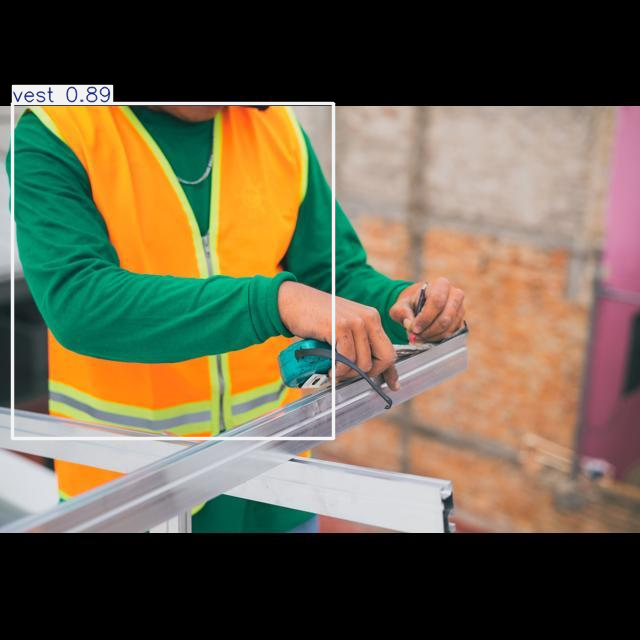

Prediction completed!


In [ ]:
from IPython.display import display
from PIL import Image

results = model.predict(
    source=image_path,
    imgsz=640,
    conf=0.25
)

# Display the image with YOLO's predicted bounding boxes
annotated_image = results[0].plot()

display(Image.fromarray(annotated_image[:, :, ::-1]))

print("Prediction completed!")

In [ ]:
for root, dirs, files in os.walk("/content"):
    for file in files:
        if "image714" in file:
            print(os.path.join(root, file))

/content/construction-ppe/labels/test/image714.txt
/content/construction-ppe/images/test/image714.jpeg


In [ ]:
results = best_model.predict(
    source="/content/construction-ppe/images/test/image714.jpeg",
    imgsz=640,
    conf=0.25,
    save=True
)

print("Prediction completed and saved.")


image 1/1 /content/construction-ppe/images/test/image714.jpeg: 640x640 1 vest, 10.7ms
Speed: 1.0ms preprocess, 10.7ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
Prediction completed and saved.


In [ ]:
import os

print("Searching for prediction folders...")

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            if "image714" in file:
                print("FOUND:", os.path.join(root, file))

Searching for prediction folders...
FOUND: /content/runs/detect/predict/image714.jpg
FOUND: /content/construction-ppe/images/test/image714.jpeg


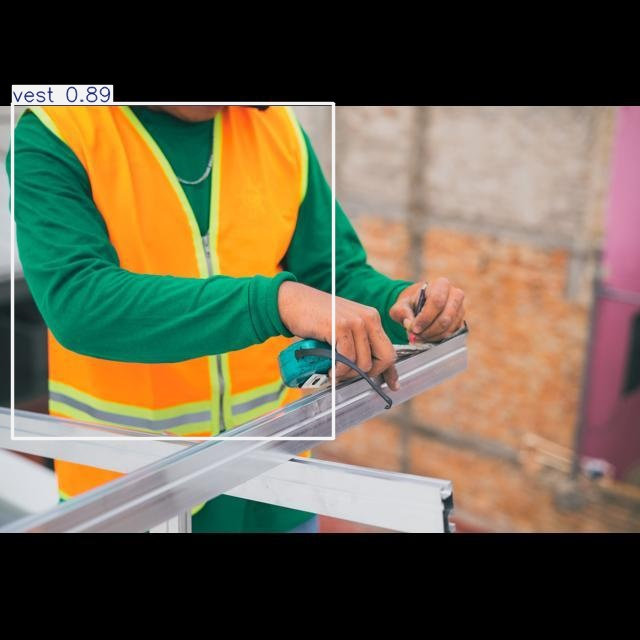

In [ ]:
from IPython.display import Image, display

display(Image(filename="/content/runs/detect/predict/image714.jpg"))

In [ ]:
results = best_model.predict(
    source="/content/construction-ppe/images/test",
    imgsz=640,
    conf=0.25,
    save=True
)

print("Prediction completed on the test images.")
print("Results saved to:", results[0].save_dir)


image 1/141 /content/construction-ppe/images/test/image1.jpeg: 640x640 1 helmet, 1 vest, 1 Person, 12.0ms
image 2/141 /content/construction-ppe/images/test/image10.jpeg: 640x640 1 helmet, 3 vests, 2 bootss, 3 Persons, 10.9ms
image 3/141 /content/construction-ppe/images/test/image1003.jpg: 640x640 1 helmet, 2 glovess, 1 vest, 2 bootss, 1 goggles, 1 Person, 10.7ms
image 4/141 /content/construction-ppe/images/test/image1007.jpg: 640x640 1 helmet, 2 glovess, 1 vest, 2 bootss, 1 goggles, 1 Person, 11.5ms
image 5/141 /content/construction-ppe/images/test/image1009.jpg: 640x640 1 helmet, 1 gloves, 1 vest, 1 boots, 1 Person, 10.8ms
image 6/141 /content/construction-ppe/images/test/image1014.jpg: 640x640 1 helmet, 2 glovess, 1 vest, 2 bootss, 1 goggles, 1 Person, 11.1ms
image 7/141 /content/construction-ppe/images/test/image1019.jpg: 640x640 1 helmet, 2 glovess, 1 vest, 2 bootss, 1 goggles, 1 Person, 11.1ms
image 8/141 /content/construction-ppe/images/test/image1023.jpg: 640x640 1 helmet, 2 gl

In [ ]:
import os

save_dir = str(results[0].save_dir)

images = [
    f for f in os.listdir(save_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Predicted images:", len(images))
print("First few:", images[:10])

Predicted images: 141
First few: ['image927.jpg', 'image182.jpg', 'image935.jpg', 'image6.jpg', 'image1306.jpg', 'image58.jpg', 'image257.jpg', 'image225.jpg', 'image536.jpg', 'image884.jpg']


In [ ]:
print(best_model.names)

{0: 'helmet', 1: 'gloves', 2: 'vest', 3: 'boots', 4: 'goggles', 5: 'none', 6: 'Person', 7: 'no_helmet', 8: 'no_goggle', 9: 'no_gloves', 10: 'no_boots'}


In [ ]:
from collections import Counter

# Predict on one test image
results = best_model.predict(
    source="/content/construction-ppe/images/test/image714.jpeg",
    imgsz=640,
    conf=0.25,
    verbose=False
)

result = results[0]

# Get detected class names
detected_classes = []

for cls_id in result.boxes.cls:
    class_id = int(cls_id)
    detected_classes.append(best_model.names[class_id])

print("Detected objects:")
print(detected_classes)

# Count detections
counts = Counter(detected_classes)

print("\nDetection summary:")
for name, count in counts.items():
    print(f"{name}: {count}")

Detected objects:
['vest']

Detection summary:
vest: 1


In [ ]:
required_ppe = {
    "helmet": "no_helmet",
    "goggles": "no_goggle",
    "gloves": "no_gloves",
    "boots": "no_boots"
}

violations = []

for safe_item, unsafe_item in required_ppe.items():
    if unsafe_item in detected_classes:
        violations.append(safe_item)

print("\n========== SAFETY REPORT ==========")

if violations:
    print("⚠️ PPE VIOLATION DETECTED")
    print("Missing/unsafe:", ", ".join(violations))
else:
    print("✅ No PPE violation detected")


========== SAFETY REPORT ==========
✅ No PPE violation detected


In [ ]:
results = best_model.predict(
    source="/content/construction-ppe/images/test",
    imgsz=640,
    conf=0.25,
    save=True,
    verbose=False
)

print("Prediction completed.")
print("Images processed:", len(results))
print("Results saved to:", results[0].save_dir)

Results saved to /content/runs/detect/predict
Prediction completed.
Images processed: 141
Results saved to: /content/runs/detect/predict


In [ ]:
from collections import Counter

total_detections = Counter()

for result in results:
    for cls_id in result.boxes.cls:
        class_id = int(cls_id)
        class_name = best_model.names[class_id]
        total_detections[class_name] += 1

print("========== DETECTION SUMMARY ==========")

for class_name, count in total_detections.items():
    print(f"{class_name}: {count}")

========== DETECTION SUMMARY ==========
helmet: 190
vest: 190
Person: 252
boots: 207
gloves: 135
goggles: 46
none: 68
no_helmet: 32
no_gloves: 18
no_goggle: 4


In [ ]:
def safety_status(detected_classes):

    violations = []

    if "no_helmet" in detected_classes:
        violations.append("No Helmet")

    if "no_goggle" in detected_classes:
        violations.append("No Goggles")

    if "no_gloves" in detected_classes:
        violations.append("No Gloves")

    if "no_boots" in detected_classes:
        violations.append("No Boots")

    if len(violations) == 0:
        return "SAFE", []

    return "VIOLATION", violations

In [ ]:
detected = ["Person", "vest", "no_helmet"]

status, violations = safety_status(detected)

print("Status:", status)
print("Violations:", violations)

Status: VIOLATION
Violations: ['No Helmet']


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 8964295-uhd_3840_2160_25fps.mp4 to 8964295-uhd_3840_2160_25fps.mp4


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'runs', 'construction-safety-runs', 'construction-ppe.zip', 'construction-ppe', 'yolo11n.pt', 'weights', '8964295-uhd_3840_2160_25fps.mp4', 'sample_data']


In [ ]:
video_path = "/content/8964295-uhd_3840_2160_25fps.mp4"

print(video_path)

/content/8964295-uhd_3840_2160_25fps.mp4


In [ ]:
video_results = best_model.predict(
    source=video_path,
    imgsz=640,
    conf=0.25,
    save=True,
    verbose=True
)

print("Video prediction completed!")
print("Output folder:", video_results[0].save_dir)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/206) /content/8964295-uhd_3840_2160_25fps.mp4: 384x640 2 helmets, 1 vest, 1 none, 2 Persons, 137.2ms
video 1/1 (frame 2/206) /content/8964295-uhd_3840_2160_25fps.mp4: 384x640 2 helmets, 1 vest, 1 none, 2 Persons, 45.4ms
video 1/1 (frame 3/206) /content/8964295-uhd_3840_2160_25fps.mp4: 384x640 1 helmet, 1 vest, 1 none, 2 Persons, 30.4ms
video 1/1 (frame 4/206) /content/8964295-uhd_3840_2160_25fps.mp4: 384x640 2 helmets, 1 vest, 1 none, 2

In [ ]:
import os

output_folder = "/content/runs/detect/predict"

print(os.listdir(output_folder))

['image927.jpg', 'image182.jpg', 'image935.jpg', 'image6.jpg', 'image1306.jpg', 'image58.jpg', 'image257.jpg', 'image225.jpg', 'image536.jpg', 'image884.jpg', 'image708.jpg', 'image810.jpg', 'image381.jpg', 'image517.jpg', 'image287.jpg', 'image987.jpg', 'image389.jpg', 'image345.jpg', 'image846.jpg', 'image825.jpg', 'image150.jpg', 'image611.jpg', 'image921.jpg', 'image1331.jpg', 'image401.jpg', 'image361.jpg', 'image459.jpg', 'image535.jpg', 'image1152.jpg', 'image1089.jpg', 'image1074.jpg', 'image1256.jpg', 'image943.jpg', 'image1111.jpg', 'image441.jpg', 'image1014.jpg', 'image1205.jpg', 'image805.jpg', 'image1009.jpg', 'image431.jpg', 'image1276.jpg', 'image481.jpg', 'image1332.jpg', 'image1088.jpg', 'image110.jpg', 'image1178.jpg', 'image393.jpg', 'image460.jpg', 'image1239.jpg', 'image462.jpg', 'image612.jpg', 'image1264.jpg', 'image296.jpg', 'image619.jpg', 'image913.jpg', 'image739.jpg', 'image633.jpg', 'image1125.jpg', 'image796.jpg', 'image538.jpg', 'image1.jpg', 'image160.j

In [ ]:
from IPython.display import Video, display
import os

video_files = [
    f for f in os.listdir(output_folder)
    if f.lower().endswith((".mp4", ".avi", ".mov"))
]

print("Video files:", video_files)

output_video = os.path.join(output_folder, video_files[0])

display(Video(output_video, embed=True))

In [ ]:

files.download(output_video)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from ultralytics import YOLO
from collections import Counter

model = YOLO(
    "/content/construction-safety-runs/yolo11n-ppe/weights/best.pt"
)

video_path = "/content/8964295-uhd_3840_2160_25fps.mp4"

class_counts = Counter()
frame_count = 0

results = model.predict(
    source=video_path,
    imgsz=640,
    conf=0.25,
    stream=True,
    verbose=False
)

for result in results:
    frame_count += 1

    for cls in result.boxes.cls:
        class_id = int(cls)
        class_name = model.names[class_id]
        class_counts[class_name] += 1

print("Frames processed:", frame_count)
print("\nDetection counts:")

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

Frames processed: 206

Detection counts:
vest: 210
Person: 412
helmet: 406
none: 206


In [ ]:
def check_safety(detected_classes):

    violations = []

    if "no_helmet" in detected_classes:
        violations.append("No Helmet")

    if "no_goggle" in detected_classes:
        violations.append("No Goggles")

    if "no_gloves" in detected_classes:
        violations.append("No Gloves")

    if "no_boots" in detected_classes:
        violations.append("No Boots")

    if len(violations) == 0:
        return "SAFE", violations

    return "VIOLATION", violations

In [ ]:
print(check_safety(["Person", "helmet", "vest"]))
print(check_safety(["Person", "no_helmet", "vest"]))
print(check_safety(["Person", "no_gloves", "no_boots"]))

('SAFE', [])
('VIOLATION', ['No Helmet'])
('VIOLATION', ['No Gloves', 'No Boots'])


In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/construction-safety-runs/yolo11n-ppe/weights/best.pt"
)

video_path = "/content/8964295-uhd_3840_2160_25fps.mp4"

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
results = model.track(
    source=video_path,
    imgsz=640,
    conf=0.25,
    tracker="bytetrack.yaml",
    persist=True,
    stream=True,
    verbose=False
)

for result in results:
    pass

print("Tracking completed!")

Tracking completed!


In [ ]:
from ultralytics import YOLO

model = YOLO(
    "/content/construction-safety-runs/yolo11n-ppe/weights/best.pt"
)

video_path = "/content/8964295-uhd_3840_2160_25fps.mp4"

results = model.track(
    source=video_path,
    imgsz=640,
    conf=0.25,
    tracker="bytetrack.yaml",
    persist=True,
    stream=True,
    verbose=False
)

worker_ids = set()
frames_checked = 0

for result in results:
    frames_checked += 1

    if result.boxes.id is not None:
        for track_id, cls in zip(
            result.boxes.id,
            result.boxes.cls
        ):
            class_name = model.names[int(cls)]

            # Only track people
            if class_name == "Person":
                worker_ids.add(int(track_id))

    # Check first 20 frames only for demonstration
    if frames_checked >= 20:
        break

print("Frames checked:", frames_checked)
print("Worker IDs detected:", sorted(worker_ids))
print("Number of workers:", len(worker_ids))

Frames checked: 20
Worker IDs detected: [2, 3]
Number of workers: 2


In [ ]:
import math
from collections import defaultdict
from ultralytics import YOLO

model = YOLO(
    "/content/construction-safety-runs/yolo11n-ppe/weights/best.pt"
)

video_path = "/content/8964295-uhd_3840_2160_25fps.mp4"

# Store PPE information for every worker
worker_data = defaultdict(lambda: {
    "helmet": 0,
    "vest": 0,
    "no_helmet": 0,
    "no_goggle": 0,
    "no_gloves": 0,
    "no_boots": 0
})


def center(box):
    x1, y1, x2, y2 = box
    return (
        (x1 + x2) / 2,
        (y1 + y2) / 2
    )


def distance(point1, point2):
    return math.sqrt(
        (point1[0] - point2[0]) ** 2 +
        (point1[1] - point2[1]) ** 2
    )


results = model.track(
    source=video_path,
    imgsz=640,
    conf=0.25,
    tracker="bytetrack.yaml",
    persist=True,
    stream=True,
    verbose=False
)

for result in results:

    if result.boxes.id is None:
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy()
    track_ids = result.boxes.id.cpu().numpy()

    people = []
    ppe_objects = []

    for box, cls, track_id in zip(boxes, classes, track_ids):

        class_name = model.names[int(cls)]

        if class_name == "Person":
            people.append({
                "id": int(track_id),
                "box": box
            })

        elif class_name in [
            "helmet",
            "vest",
            "no_helmet",
            "no_goggle",
            "no_gloves",
            "no_boots"
        ]:
            ppe_objects.append({
                "class": class_name,
                "box": box
            })

    # Associate each PPE object with nearest worker
    for ppe in ppe_objects:

        ppe_center = center(ppe["box"])

        nearest_person = None
        nearest_distance = float("inf")

        for person in people:

            person_center = center(person["box"])

            d = distance(
                ppe_center,
                person_center
            )

            if d < nearest_distance:
                nearest_distance = d
                nearest_person = person

        if nearest_person is not None:

            worker_id = nearest_person["id"]
            ppe_class = ppe["class"]

            worker_data[worker_id][ppe_class] += 1


print("\nWorker PPE Analysis")
print("=" * 40)

for worker_id, data in worker_data.items():

    print(f"\nWorker ID: {worker_id}")

    for item, count in data.items():
        print(f"{item}: {count}")


Worker PPE Analysis

Worker ID: 2
helmet: 200
vest: 206
no_helmet: 0
no_goggle: 0
no_gloves: 0
no_boots: 0

Worker ID: 3
helmet: 206
vest: 0
no_helmet: 0
no_goggle: 0
no_gloves: 0
no_boots: 0


In [ ]:
for worker_id, data in worker_data.items():

    violations = []

    if data["no_helmet"] > 0:
        violations.append("No Helmet")

    if data["no_goggle"] > 0:
        violations.append("No Goggles")

    if data["no_gloves"] > 0:
        violations.append("No Gloves")

    if data["no_boots"] > 0:
        violations.append("No Boots")

    if len(violations) > 0:
        status = "VIOLATION"
    else:
        status = "SAFE"

    print("\n" + "=" * 40)
    print(f"Worker ID : {worker_id}")
    print(f"Status    : {status}")

    if violations:
        print("Violations:", ", ".join(violations))
    else:
        print("Violations: None")

    print(f"Helmet detections : {data['helmet']}")
    print(f"Vest detections   : {data['vest']}")


Worker ID : 2
Status    : SAFE
Violations: None
Helmet detections : 200
Vest detections   : 206

Worker ID : 3
Status    : SAFE
Violations: None
Helmet detections : 206
Vest detections   : 0


In [ ]:
total_frames = 206

for worker_id, data in worker_data.items():

    helmet_percentage = (
        data["helmet"] / total_frames
    ) * 100

    vest_percentage = (
        data["vest"] / total_frames
    ) * 100

    print("\n" + "=" * 40)
    print(f"Worker ID: {worker_id}")

    print(f"Helmet compliance: {helmet_percentage:.1f}%")
    print(f"Vest compliance:   {vest_percentage:.1f}%")


Worker ID: 2
Helmet compliance: 97.1%
Vest compliance:   100.0%

Worker ID: 3
Helmet compliance: 100.0%
Vest compliance:   0.0%


In [ ]:
import pandas as pd

total_frames = 206

report = []

for worker_id, data in worker_data.items():

    helmet_pct = (data["helmet"] / total_frames) * 100
    vest_pct = (data["vest"] / total_frames) * 100

    violations = []

    if data["no_helmet"] > 0:
        violations.append("No Helmet")

    if data["no_goggle"] > 0:
        violations.append("No Goggles")

    if data["no_gloves"] > 0:
        violations.append("No Gloves")

    if data["no_boots"] > 0:
        violations.append("No Boots")

    # Determine status
    if violations:
        status = "VIOLATION"
    elif vest_pct < 20:
        status = "REVIEW"
    else:
        status = "SAFE"

    report.append({
        "Worker ID": worker_id,
        "Helmet Compliance %": round(helmet_pct, 1),
        "Vest Compliance %": round(vest_pct, 1),
        "Violations": ", ".join(violations) if violations else "None",
        "Status": status
    })

df_report = pd.DataFrame(report)

df_report

,Worker ID,Helmet Compliance %,Vest Compliance %,Violations,Status
0,2,97.1,100.0,None,SAFE
1,3,100.0,0.0,None,REVIEW


In [ ]:
total_workers = len(df_report)

safe_workers = (df_report["Status"] == "SAFE").sum()
review_workers = (df_report["Status"] == "REVIEW").sum()
violation_workers = (df_report["Status"] == "VIOLATION").sum()

print("======================================")
print("   CONSTRUCTION SAFETY SUMMARY")
print("======================================")

print(f"Total Workers     : {total_workers}")
print(f"Safe Workers      : {safe_workers}")
print(f"Review Required   : {review_workers}")
print(f"Violations        : {violation_workers}")

print("======================================")

   CONSTRUCTION SAFETY SUMMARY
Total Workers     : 2
Safe Workers      : 1
Review Required   : 1
Violations        : 0


In [ ]:
overall_helmet = df_report["Helmet Compliance %"].mean()
overall_vest = df_report["Vest Compliance %"].mean()

print(f"Overall Helmet Compliance: {overall_helmet:.1f}%")
print(f"Overall Vest Compliance:   {overall_vest:.1f}%")

Overall Helmet Compliance: 98.5%
Overall Vest Compliance:   50.0%


In [ ]:
from google.colab import files

files.download(
    "/content/construction-safety-runs/yolo11n-ppe/weights/best.pt"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

NameError: name 'g' is not defined